# Heart Failure Prediction — Feature Dictionary

Below is a brief overview of the clinical features used in this dataset:

1. **ChestPainType**: Type of chest pain experienced by the patient.
   - `TA`: Typical Angina (chest pain directly related to reduced blood flow to the heart)
   - `ATA`: Atypical Angina (chest pain not clearly linked to the heart)
   - `NAP`: Non-Anginal Pain (chest pain unrelated to the heart)
   - `ASY`: Asymptomatic (no chest pain symptoms)
2. **RestingBP**: Resting blood pressure measured upon admission (in `mm Hg`).
3. **Cholesterol**: Serum cholesterol level in the blood (in `mg/dL`).
4. **FastingBS**: Fasting blood sugar level (`1` if > 120 mg/dL, `0` otherwise).
5. **RestingECG**: Resting electrocardiogram (ECG) results.
   - `Normal`: Normal heart electrical activity
   - `ST`: ST-T wave abnormality
   - `LVH`: Probable or definite left ventricular hypertrophy (thickened heart wall)
6. **MaxHR**: Maximum heart rate achieved during exercise testing (in beats per minute, `bpm`).
7. **ExerciseAngina**: Whether physical exercise triggers chest pain (`Y`: Yes, `N`: No).
8. **Oldpeak**: ST-segment depression induced by exercise relative to rest; reflects reduced blood flow to the heart muscle.
9. **ST_Slope**: The slope direction of the peak exercise ST segment on the ECG (`Up`: Upsloping, `Flat`: Horizontal, `Down`: Downsloping).

# 1. import library

In [5]:
# manipulation data
import pandas as pd
import numpy as np

#visualiation data
import matplotlib.pyplot as plt
import seaborn as sns 
import matplotlib
import plotly.graph_objects as go
import plotly.express as px

#default theme
sns.set(context='notebook', style='darkgrid', palette='colorblind', font='sans-serif', font_scale=1, rc=None)
matplotlib.rcParams['figure.figsize'] =[8,8]
matplotlib.rcParams.update({'font.size': 15})
matplotlib.rcParams['font.family'] = 'sans-serif'

# 2. data analysis

In [6]:
train = pd.read_csv('C:/Project-Heart-Failure-Prediction-End-To-End/data/heart.csv')
train.head(6)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0


In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 97.6 KB


In [8]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in train.select_dtypes(include='object').columns:
  train[col] = le.fit_transform(train[col])

C:\Users\MediaCenter\AppData\Local\Temp\ipykernel_22304\1038736793.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in train.select_dtypes(include='object').columns:


In [9]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    int64  
 2   ChestPainType   918 non-null    int64  
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    int64  
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    int64  
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    int64  
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(11)
memory usage: 86.2 KB


In [10]:
train.head(10)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,1,140,289,0,1,172,0,0.0,2,0
1,49,0,2,160,180,0,1,156,0,1.0,1,1
2,37,1,1,130,283,0,2,98,0,0.0,2,0
3,48,0,0,138,214,0,1,108,1,1.5,1,1
4,54,1,2,150,195,0,1,122,0,0.0,2,0
5,39,1,2,120,339,0,1,170,0,0.0,2,0
6,45,0,1,130,237,0,1,170,0,0.0,2,0
7,54,1,1,110,208,0,1,142,0,0.0,2,0
8,37,1,0,140,207,0,1,130,1,1.5,1,1
9,48,0,1,120,284,0,1,120,0,0.0,2,0


# 3. finding missing values

In [11]:
train.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

### 4.Cleaning Data

In [12]:
null_summary = pd.DataFrame({
    'Missing (NaN)': train.isnull().sum(),
    'Percentage (%)': (train.isnull().sum() / len(train)) * 100
})
print(null_summary)

num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']
print("\n The zeros are unpronounced.")
for col in num_cols:
    print(f"{col} == 0 : {(train[col] == 0).sum()}")

                Missing (NaN)  Percentage (%)
Age                         0             0.0
Sex                         0             0.0
ChestPainType               0             0.0
RestingBP                   0             0.0
Cholesterol                 0             0.0
FastingBS                   0             0.0
RestingECG                  0             0.0
MaxHR                       0             0.0
ExerciseAngina              0             0.0
Oldpeak                     0             0.0
ST_Slope                    0             0.0
HeartDisease                0             0.0

 The zeros are unpronounced.
Age == 0 : 0
RestingBP == 0 : 1
Cholesterol == 0 : 172
MaxHR == 0 : 0


In [13]:
# 1. Replacing zeros in RestingBP with the median
median_bp = train.loc[train['RestingBP'] > 0, 'RestingBP'].median()
train['RestingBP'] = train['RestingBP'].replace(0, median_bp)

# 2. Imputing the 172 zeros in 'Cholesterol' with the median
median_chol = train.loc[train['Cholesterol'] > 0, 'Cholesterol'].median()
train['Cholesterol'] = train['Cholesterol'].replace(0, median_chol)
print("Complet Cleaning Data")

Complet Cleaning Data


In [14]:
null_summary = pd.DataFrame({
    'Missing (NaN)': train.isnull().sum(),
    'Percentage (%)': (train.isnull().sum() / len(train)) * 100
})
print(null_summary)

num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR']
print("\n The zeros are unpronounced.")
for col in num_cols:
    print(f"{col} == 0 : {(train[col] == 0).sum()}")

                Missing (NaN)  Percentage (%)
Age                         0             0.0
Sex                         0             0.0
ChestPainType               0             0.0
RestingBP                   0             0.0
Cholesterol                 0             0.0
FastingBS                   0             0.0
RestingECG                  0             0.0
MaxHR                       0             0.0
ExerciseAngina              0             0.0
Oldpeak                     0             0.0
ST_Slope                    0             0.0
HeartDisease                0             0.0

 The zeros are unpronounced.
Age == 0 : 0
RestingBP == 0 : 0
Cholesterol == 0 : 0
MaxHR == 0 : 0


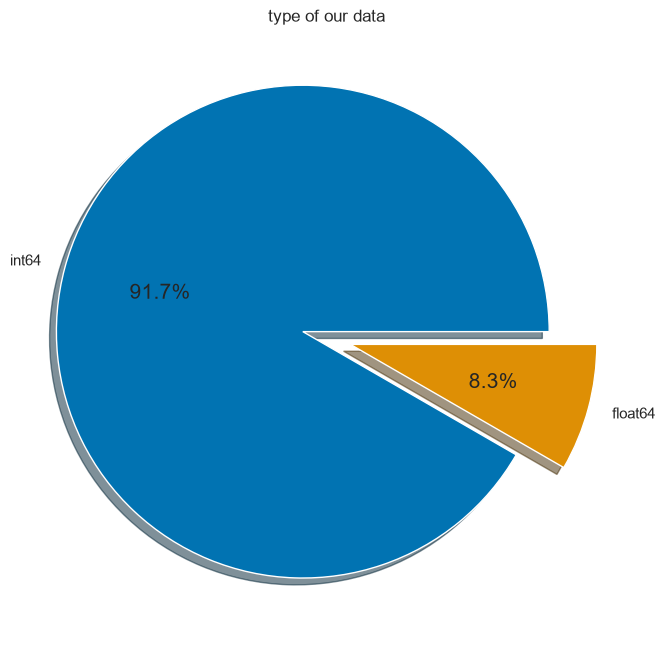

In [15]:
train.dtypes.value_counts().plot.pie(explode=[0.1,0.1],autopct='%1.1f%%',shadow=True)
plt.title('type of our data');

In [16]:
train.columns #and Search

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='str')

In [17]:
train.describe()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,0.789760,0.781046,132.538126,243.204793,0.233115,0.989107,136.809368,0.404139,0.887364,1.361656,0.553377
std,9.432617,0.407701,0.956519,17.990127,53.401297,0.423046,0.631671,25.460334,0.490992,1.066570,0.607056,0.497414
min,28.000000,0.000000,0.000000,80.000000,85.000000,0.000000,0.000000,60.000000,0.000000,-2.600000,0.000000,0.000000
25%,47.000000,1.000000,0.000000,120.000000,214.000000,0.000000,1.000000,120.000000,0.000000,0.000000,1.000000,0.000000
50%,54.000000,1.000000,0.000000,130.000000,237.000000,0.000000,1.000000,138.000000,0.000000,0.600000,1.000000,1.000000
75%,60.000000,1.000000,2.000000,140.000000,267.000000,0.000000,1.000000,156.000000,1.000000,1.500000,2.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,603.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,1.000000


# 4. visualization

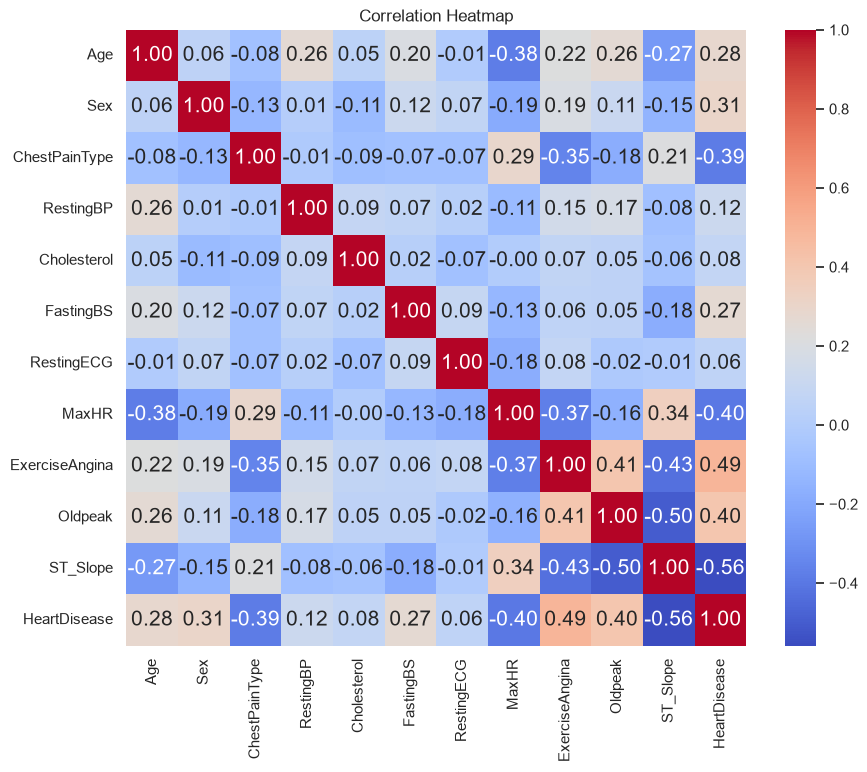

In [18]:
#Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(train.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

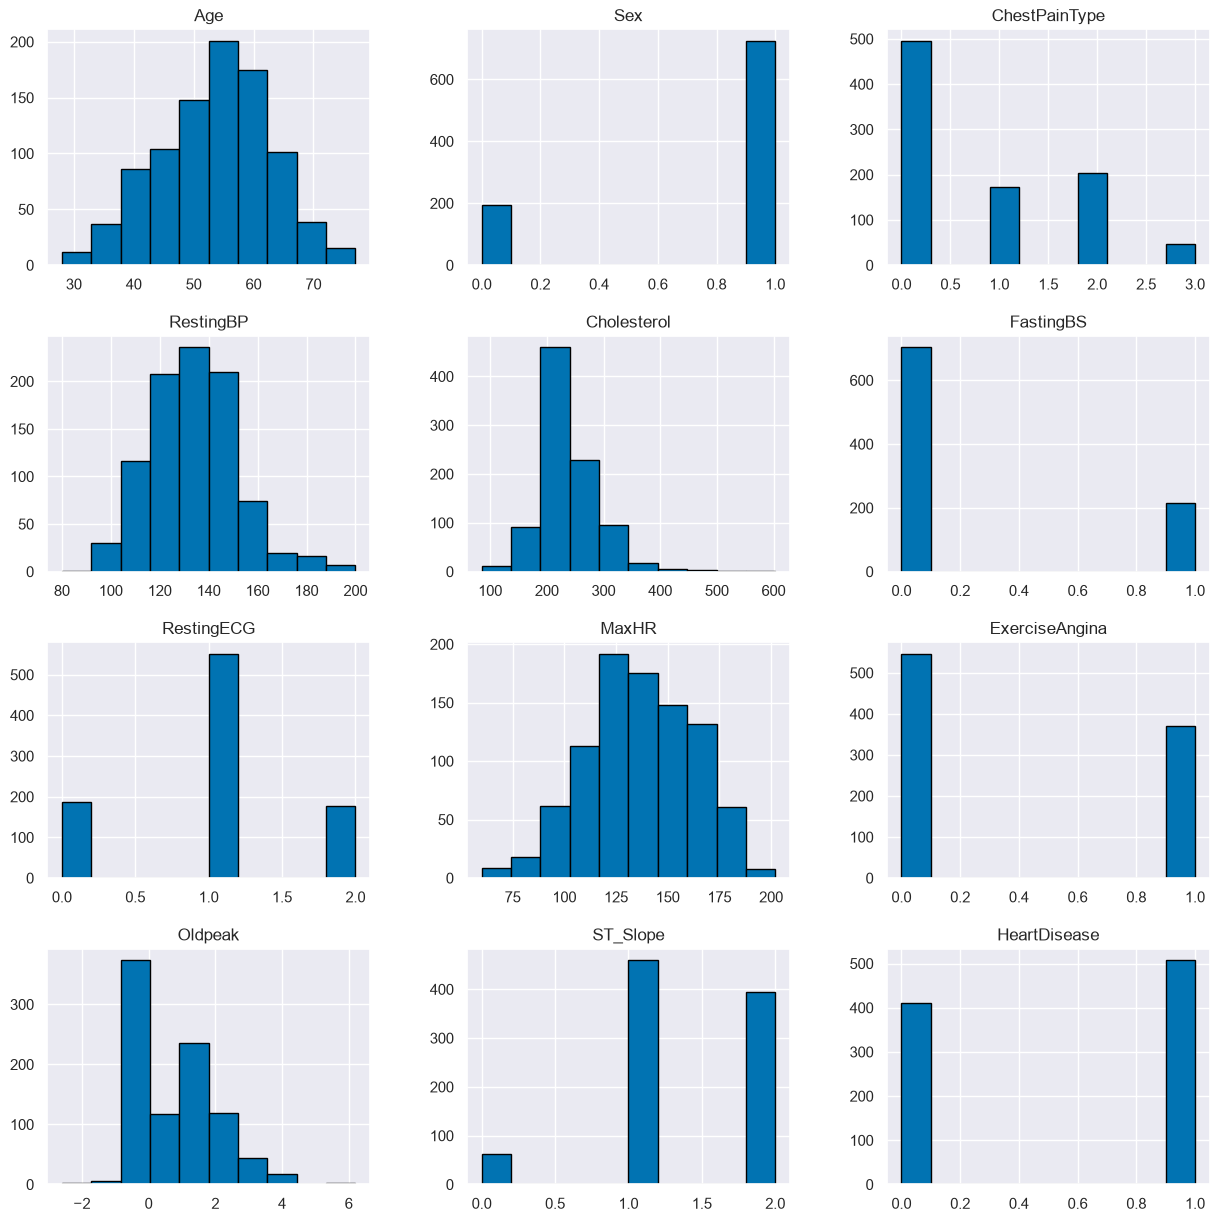

In [19]:
train.hist(figsize=(15,15),edgecolor='black');

### Heart Disease

Text(0, 0.5, '')

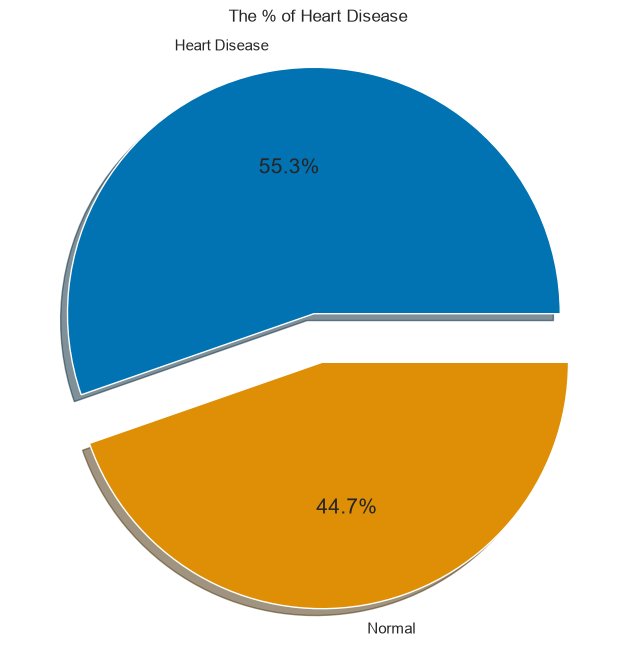

In [20]:
# Clarification of the Heat Disease rate in the data
train.HeartDisease.map({1: 'Heart Disease', 0: 'Normal'}).value_counts().plot.pie(
    explode=[0.1, 0.1],
    autopct='%1.1f%%',
    shadow=True
)
plt.title('The % of Heart Disease')
plt.ylabel('') 

### Age

Text(0.5, 1.0, 'the ages of our persone')

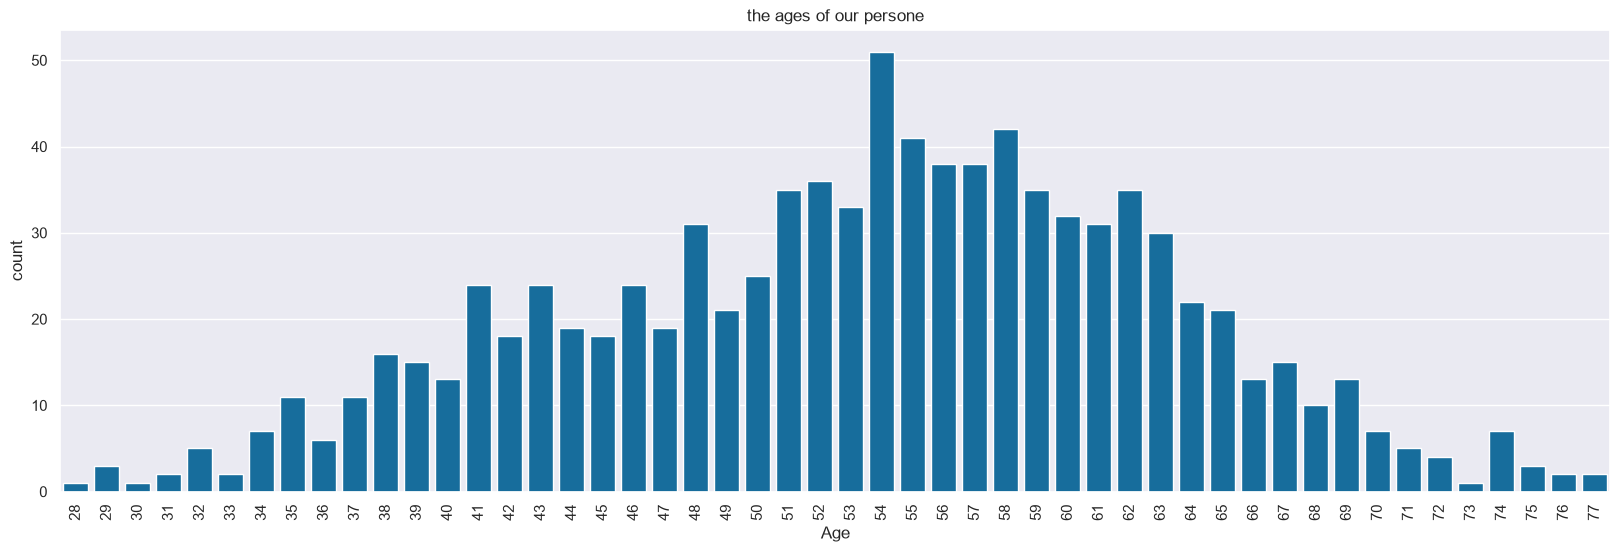

In [21]:
# Clarification of the Age rate in the data
plt.figure(figsize=(20,6))
sns.countplot(x='Age',data=train)
plt.xticks(rotation=90)
plt.title('the ages of our persone')

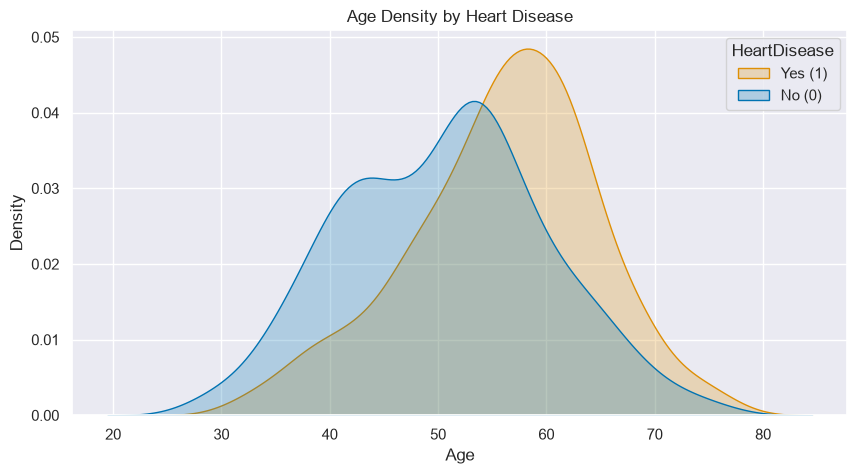

In [22]:
# Distribution of AGE Vs HeartDisease
plt.figure(figsize=(10, 5))
sns.kdeplot(data=train, x='Age', hue='HeartDisease', fill=True, common_norm=False)
plt.title('Age Density by Heart Disease')
plt.legend(title='HeartDisease', labels=['Yes (1)', 'No (0)'])
plt.show()

### sex

Text(0, 0.5, '')

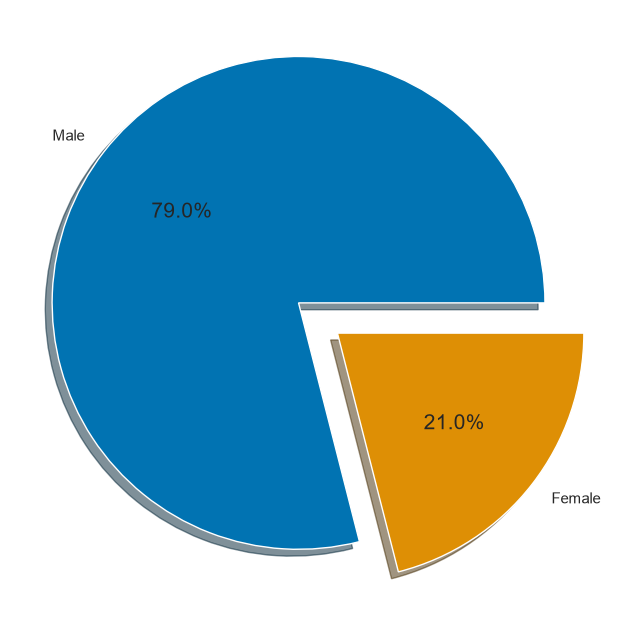

In [23]:
# Clarification of the Sex rate in the data
train.Sex.map({1: 'Male', 0: 'Female'}).value_counts().plot.pie(
    explode=[0.1, 0.1],
    autopct='%1.1f%%',
    shadow=True
)
plt.ylabel('')

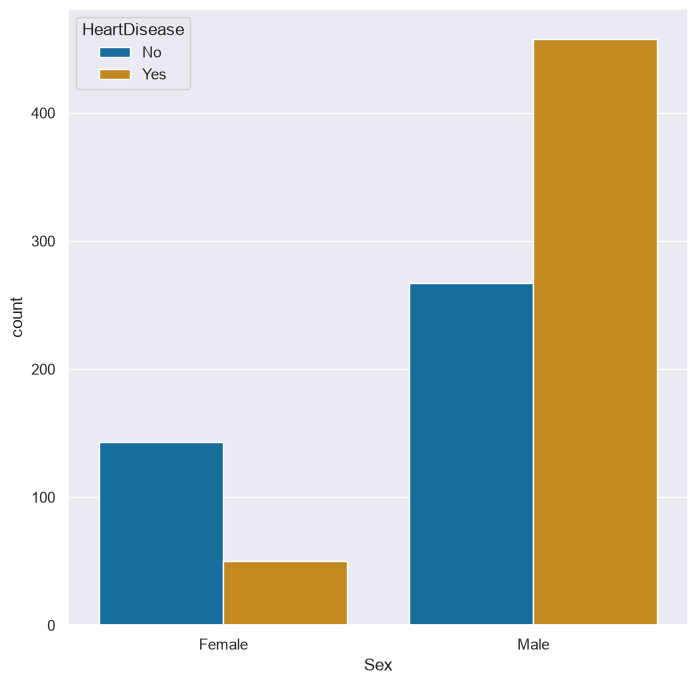

In [24]:
# Distribution of Sex Vs HeartDisease
sns.countplot(x='Sex', hue='HeartDisease', data=train)
plt.xticks([0, 1], ['Female', 'Male'])
plt.legend(title='HeartDisease', labels=['No', 'Yes'])

In [25]:
# Distribution of AGE Vs HeartDisease
import plotly.graph_objects as go
from plotly.subplots import make_subplots

d1 = train[(train["HeartDisease"]==0) & (train["Sex"]==1)]
d2 = train[(train["HeartDisease"]==1) & (train["Sex"]==1)]
d3 = train[(train["HeartDisease"]==0) & (train["Sex"]==0)]
d4 = train[(train["HeartDisease"]==1) & (train["Sex"]==0)]

label1 = ["Male","Female"]
label2 = ['Male - Normal','Male - Heart Disease', "Female -  Normal", "Female - Heart Disease"]

values1 = [(len(d1)+len(d2)), (len(d3)+len(d4))]
values2 = [len(d1),len(d2),len(d3),len(d4)]

# Create subplots: use 'domain' type for Pie subplot
fig = make_subplots(rows=1, cols=2, specs=[[{'type':'domain'}, {'type':'domain'}]])
fig.add_trace(go.Pie(labels=label1, values=values1, name="GENDER"),
              1, 1)
fig.add_trace(go.Pie(labels=label2, values=values2, name="GENDER VS HeartDisease"),
              1, 2)

# Use `hole` to create a donut-like pie chart
fig.update_traces(hole=.4, hoverinfo="label+percent")

fig.update_layout(
    title_text="Gender Distribution In THE Dataset  \
                   Gender VS HeartDisease",
    # Add annotations in the center of the donut pies.
    annotations=[dict(text='Gender', x=0.19, y=0.5, font_size=10, showarrow=False),
                 dict(text='Gender VS HeartDisease', x=0.84, y=0.5, font_size=9, showarrow=False)],
    autosize=False,width=1200, height=500, paper_bgcolor="white")

fig.show()

### ChestPainType

Text(0, 0.5, '')

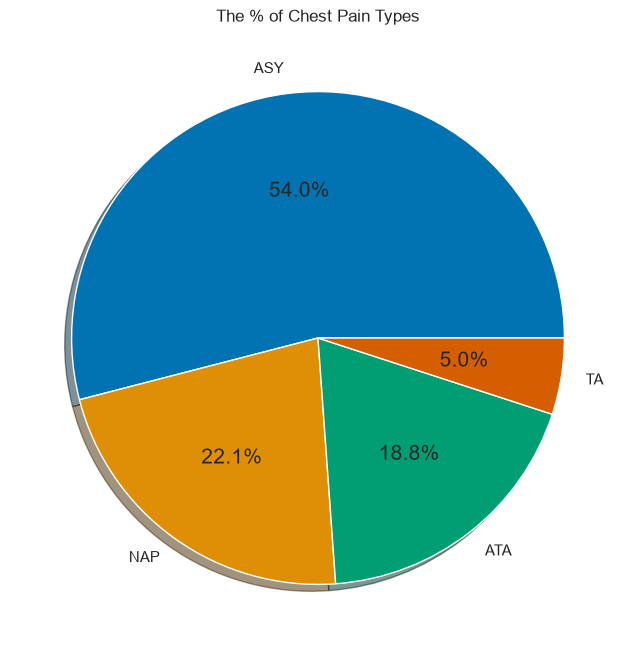

In [26]:
# Clarification regarding ChestPain Type in the data
chest_pain_map = {
    0: 'ASY',
    1: 'ATA',
    2: 'NAP',
    3: 'TA'
}

train['ChestPainType'].map(chest_pain_map).value_counts().plot.pie(
    autopct='%1.1f%%',
    shadow=True
)
plt.title('The % of Chest Pain Types')
plt.ylabel('')

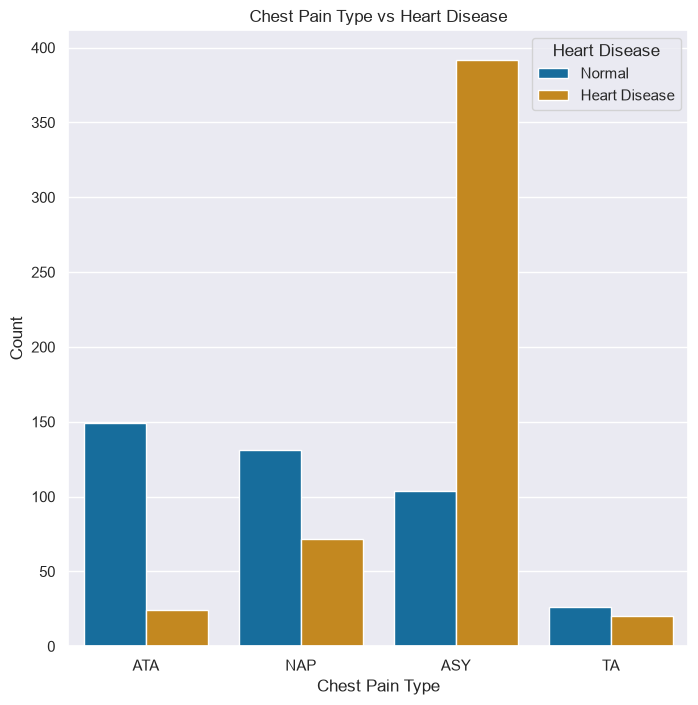

In [27]:
# Distribution of ChestPainType Vs HeartDisease
chest_pain_map = {0: 'ASY', 1: 'ATA', 2: 'NAP', 3: 'TA'}

sns.countplot(
    x=train['ChestPainType'].map(chest_pain_map),
    hue=train['HeartDisease'].map({0: 'Normal', 1: 'Heart Disease'})
)
plt.title('Chest Pain Type vs Heart Disease')
plt.xlabel('Chest Pain Type')
plt.ylabel('Count')
plt.legend(title='Heart Disease')
plt.show()

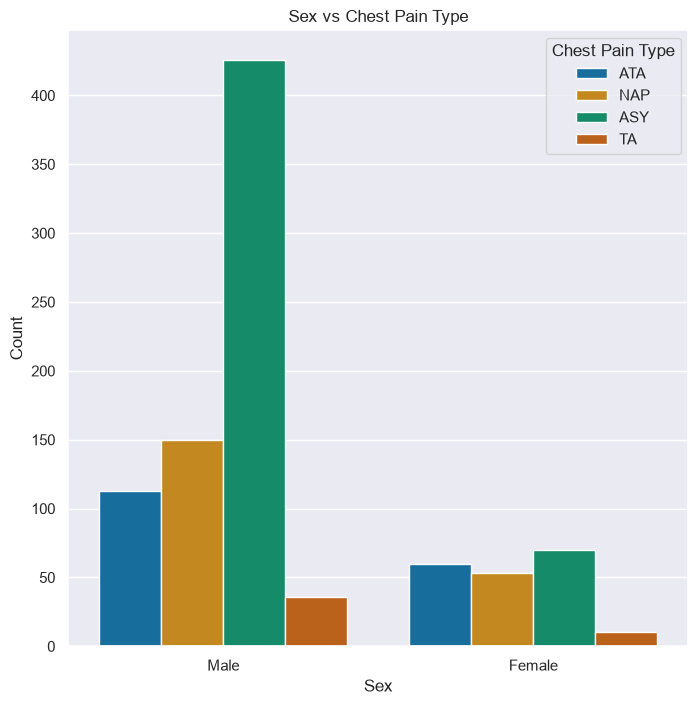

In [28]:
# Distribution of Sex Vs ChestPain Type
chest_pain_map = {0: 'ASY', 1: 'ATA', 2: 'NAP', 3: 'TA'}
sex_map = {0: 'Female', 1: 'Male'}

sns.countplot(
    x=train['Sex'].map(sex_map),
    hue=train['ChestPainType'].map(chest_pain_map)
)
plt.title('Sex vs Chest Pain Type')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.legend(title='Chest Pain Type')
plt.show()

### Cholesterol

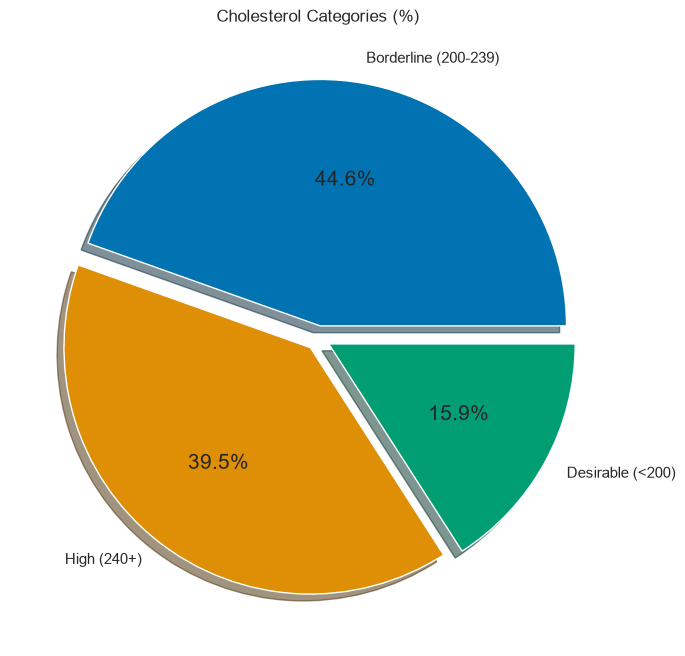

In [29]:
# Clarification regarding Cholesterol in the data
chol_level = pd.cut(
    train['Cholesterol'],
    bins=[0, 199, 239, 700],
    labels=['Desirable (<200)', 'Borderline (200-239)', 'High (240+)']
)

chol_level.value_counts().plot.pie(
    autopct='%1.1f%%',
    explode=[0.05, 0.05, 0.05],
    shadow=True
)
plt.title('Cholesterol Categories (%)')
plt.ylabel('')
plt.show()

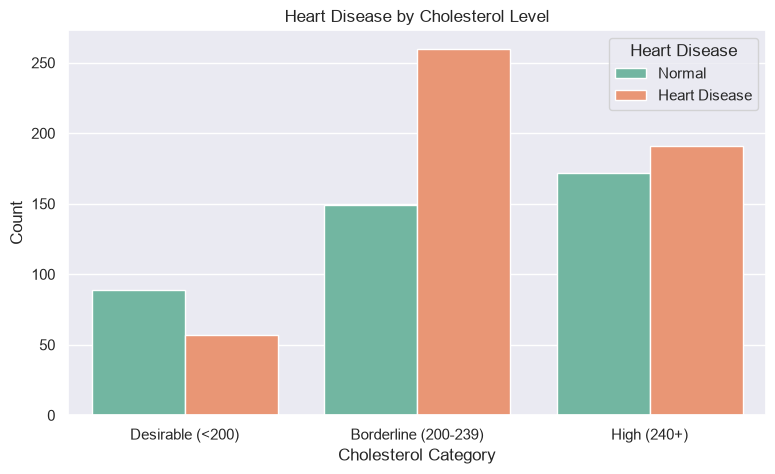

In [30]:
# Distribution of Cholesterol Leverl Vs Heart Disease
chol_level = pd.cut(
    train['Cholesterol'],
    bins=[0, 199, 239, 700],
    labels=['Desirable (<200)', 'Borderline (200-239)', 'High (240+)']
)

plt.figure(figsize=(9, 5))
sns.countplot(
    x=chol_level,
    hue=train['HeartDisease'].map({0: 'Normal', 1: 'Heart Disease'}),
    palette='Set2'
)
plt.title('Heart Disease by Cholesterol Level')
plt.xlabel('Cholesterol Category')
plt.ylabel('Count')
plt.legend(title='Heart Disease')
plt.show()

### MaxHR

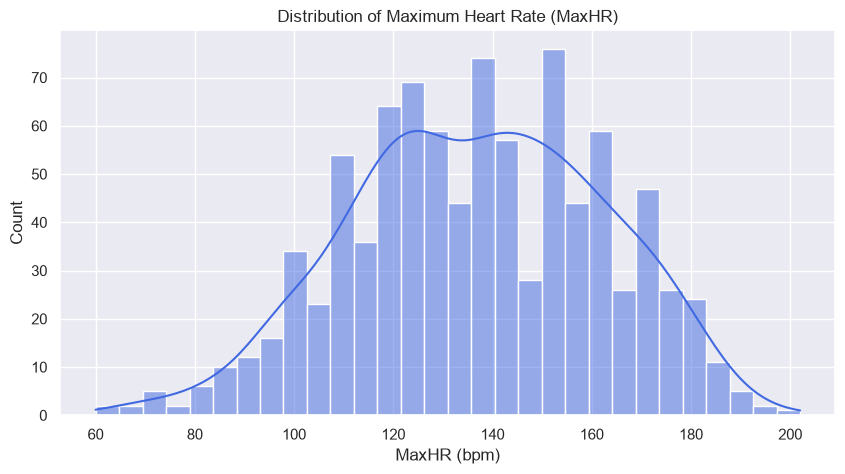

In [31]:
# Clarification regarding MaxHR in the data
plt.figure(figsize=(10, 5))
sns.histplot(data=train, x='MaxHR', kde=True, bins=30, color='royalblue')
plt.title('Distribution of Maximum Heart Rate (MaxHR)')
plt.xlabel('MaxHR (bpm)')
plt.ylabel('Count')
plt.show()

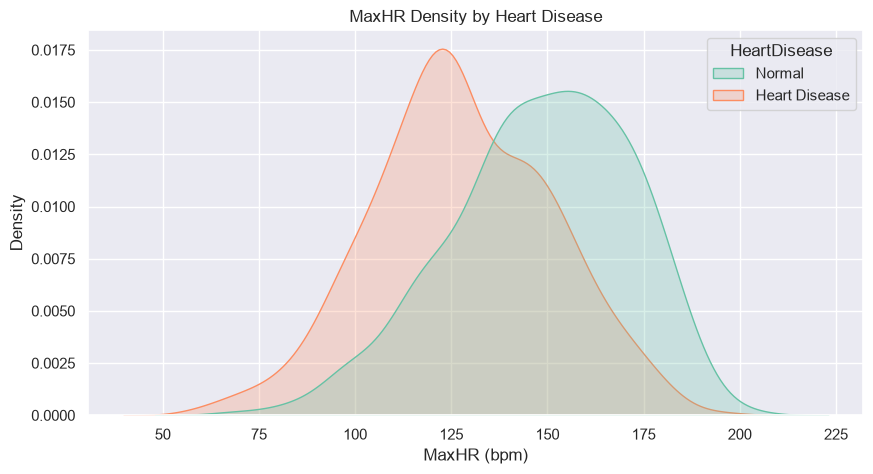

In [32]:
# Distribution of MaxHR Vs Heart Disease
plt.figure(figsize=(10, 5))
sns.kdeplot(
    data=train,
    x='MaxHR',
    hue=train['HeartDisease'].map({0: 'Normal', 1: 'Heart Disease'}),
    fill=True,
    common_norm=False,
    palette='Set2'
)
plt.title('MaxHR Density by Heart Disease')
plt.xlabel('MaxHR (bpm)')
plt.ylabel('Density')
plt.show()

### ExerciseAngina

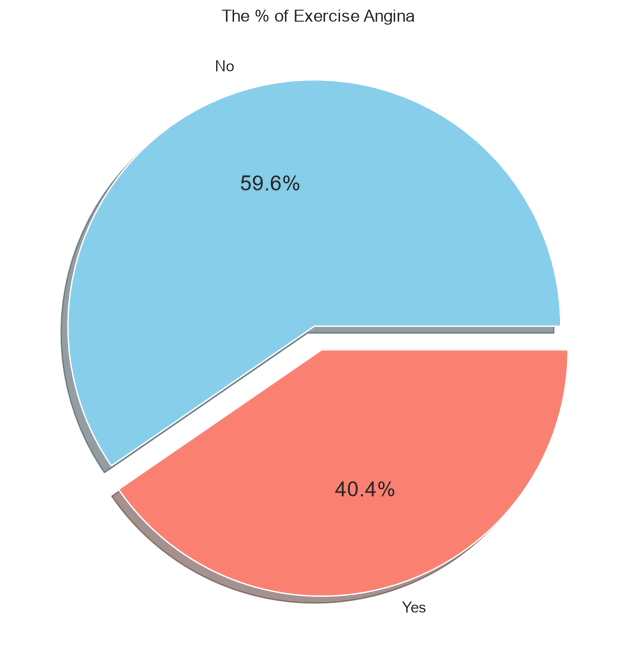

In [33]:
# Clarification regarding ExerciseAngina in the data
train['ExerciseAngina'].map({0: 'No', 1: 'Yes'}).value_counts().plot.pie(
    explode=[0.05, 0.05],
    autopct='%1.1f%%',
    shadow=True,
    colors=['skyblue', 'salmon']
)
plt.title('The % of Exercise Angina')
plt.ylabel('')
plt.show()

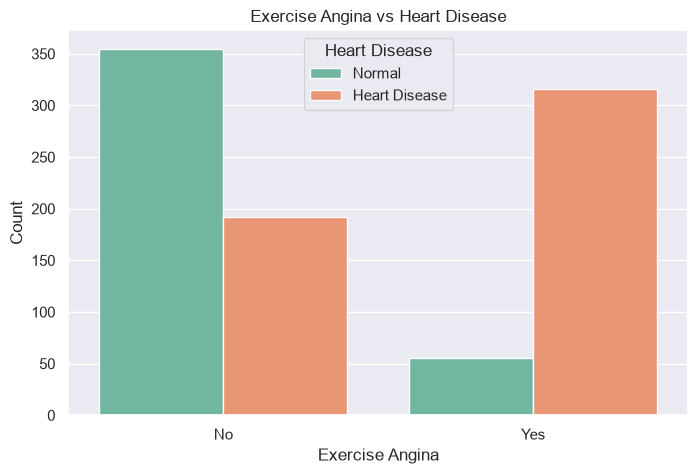

In [34]:
# Distribution of ExerciseAngina Vs Heart Disease
plt.figure(figsize=(8, 5))
sns.countplot(
    x=train['ExerciseAngina'].map({0: 'No', 1: 'Yes'}),
    hue=train['HeartDisease'].map({0: 'Normal', 1: 'Heart Disease'}),
    palette='Set2'
)
plt.title('Exercise Angina vs Heart Disease')
plt.xlabel('Exercise Angina')
plt.ylabel('Count')
plt.legend(title='Heart Disease')
plt.show()

### Oldpeak

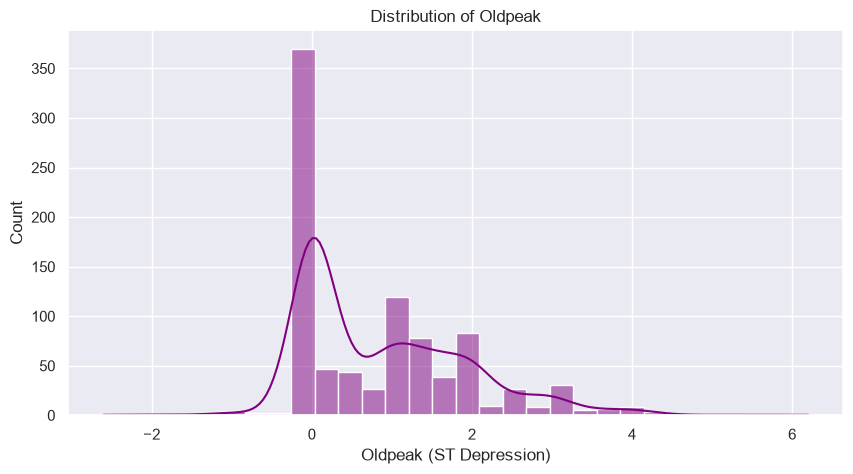

In [35]:
# Clarification regarding Oldpeak in the data
plt.figure(figsize=(10, 5))
sns.histplot(data=train, x='Oldpeak', kde=True, bins=30, color='purple')
plt.title('Distribution of Oldpeak')
plt.xlabel('Oldpeak (ST Depression)')
plt.ylabel('Count')
plt.show()

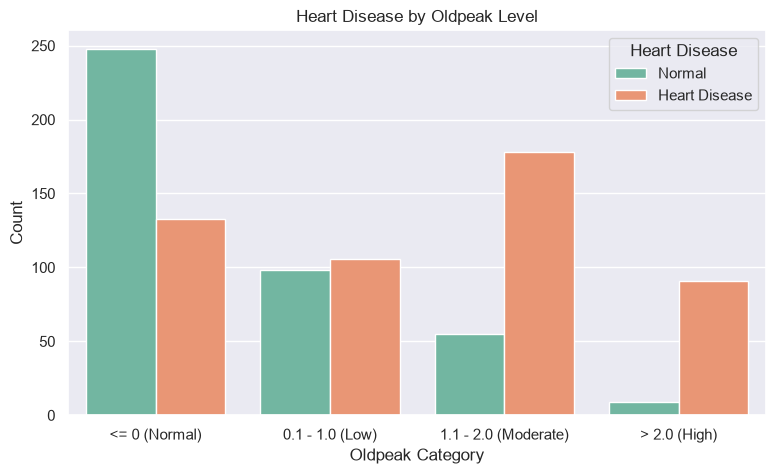

In [36]:
# Distribution of Oldpeak Vs Heart Disease
oldpeak_groups = pd.cut(
    train['Oldpeak'],
    bins=[-5, 0, 1, 2, 10],
    labels=['<= 0 (Normal)', '0.1 - 1.0 (Low)', '1.1 - 2.0 (Moderate)', '> 2.0 (High)']
)

plt.figure(figsize=(9, 5))
sns.countplot(
    x=oldpeak_groups,
    hue=train['HeartDisease'].map({0: 'Normal', 1: 'Heart Disease'}),
    palette='Set2'
)
plt.title('Heart Disease by Oldpeak Level')
plt.xlabel('Oldpeak Category')
plt.ylabel('Count')
plt.legend(title='Heart Disease')
plt.show()

### ST_Slope

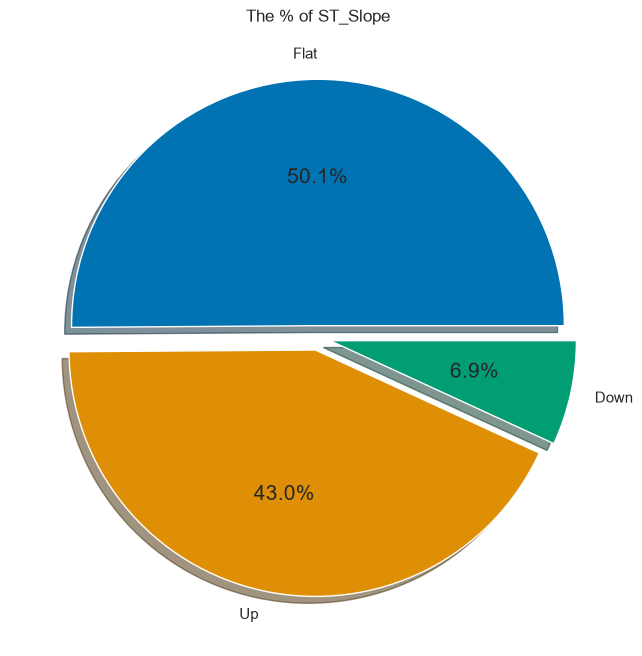

In [37]:
# Clarification regarding ST_Slope in the data
slope_map = {0: 'Down', 1: 'Flat', 2: 'Up'}

train['ST_Slope'].map(slope_map).value_counts().plot.pie(
    explode=[0.05, 0.05, 0.05],
    autopct='%1.1f%%',
    shadow=True
)
plt.title('The % of ST_Slope')
plt.ylabel('')
plt.show()

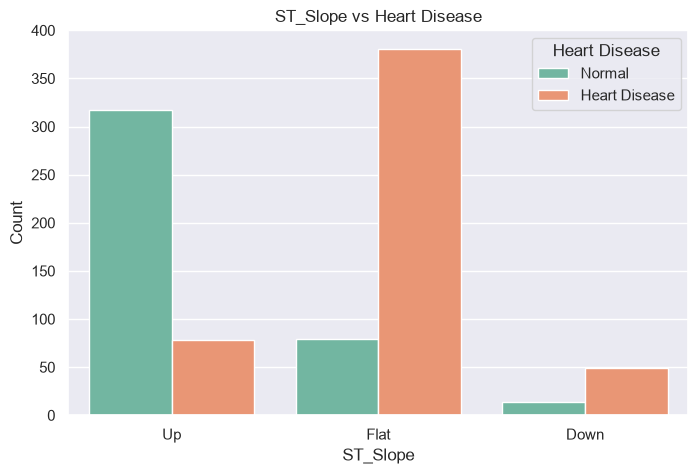

In [38]:
# # Distribution of ST_Slope Vs Heart Disease
slope_map = {0: 'Down', 1: 'Flat', 2: 'Up'}

plt.figure(figsize=(8, 5))
sns.countplot(
    x=train['ST_Slope'].map(slope_map),
    hue=train['HeartDisease'].map({0: 'Normal', 1: 'Heart Disease'}),
    palette='Set2'
)
plt.title('ST_Slope vs Heart Disease')
plt.xlabel('ST_Slope')
plt.ylabel('Count')
plt.legend(title='Heart Disease')
plt.show()

 ### Split Data And Scaling

In [39]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Separating the input variables (X) from the target column (y)
X = train.drop('HeartDisease', axis=1)
y = train['HeartDisease']

# 2. Data splitting: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Scaling the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Verifying data dimensions after splitting
print("X_train shape:", X_train_scaled.shape)
print("X_test shape:", X_test_scaled.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (734, 11)
X_test shape: (184, 11)
y_train shape: (734,)
y_test shape: (184,)


### Models

In [40]:
# لو xgboost أو catboost مش متثبتين عندك، شيل علامة # من السطر الجاي وشغله مرة واحدة
# !pip install xgboost catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve

# قاموس لتخزين دقة كل موديل للمقارنة النهائية
model_accuracies = {}

# دالة لرسم منحنى التدريب + مصفوفة الخطأ
def plot_training_and_cm(model, model_name, y_pred):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    
    # 1. منحنى التدريب (Training vs Validation Accuracy)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train_scaled, y_train, cv=5, scoring='accuracy',
        n_jobs=-1, train_sizes=np.linspace(0.2, 1.0, 5)
    )
    axes[0].plot(train_sizes, train_scores.mean(axis=1) * 100, 'o-', label='Training Accuracy')
    axes[0].plot(train_sizes, val_scores.mean(axis=1) * 100, 'o-', label='Validation Accuracy')
    axes[0].set_title(f'{model_name} - Learning Curve')
    axes[0].set_xlabel('Training Examples')
    axes[0].set_ylabel('Accuracy (%)')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # 2. مصفوفة الخطأ (Confusion Matrix)
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Heart Disease']).plot(
        ax=axes[1], cmap='Blues', colorbar=False
    )
    axes[1].set_title(f'{model_name} - Confusion Matrix')
    
    plt.tight_layout()
    plt.show()

### 1. Support Vector Machines (SVM)

In [41]:
from sklearn.svm import SVC

svm_model = SVC(random_state=42)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
acc_svm = accuracy_score(y_test, y_pred_svm) * 100
model_accuracies['SVM'] = round(acc_svm, 2)

print(f"SVM Accuracy: {acc_svm:.2f}%")

SVM Accuracy: 85.87%


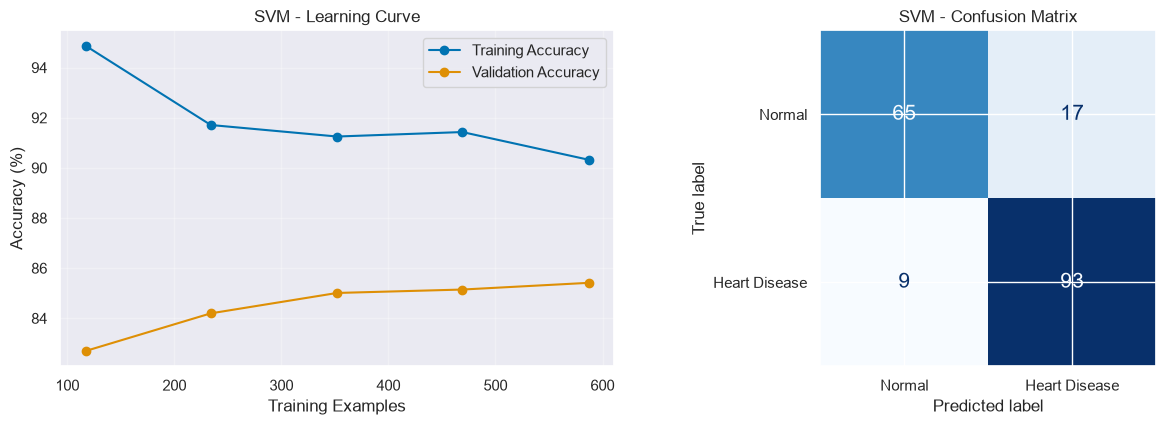

In [42]:
plot_training_and_cm(svm_model, 'SVM', y_pred_svm)

### 2. K-Nearest Neighbors (KNN)

In [43]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
acc_knn = accuracy_score(y_test, y_pred_knn) * 100
model_accuracies['KNN'] = round(acc_knn, 2)

print(f"KNN Accuracy: {acc_knn:.2f}%")

KNN Accuracy: 86.41%


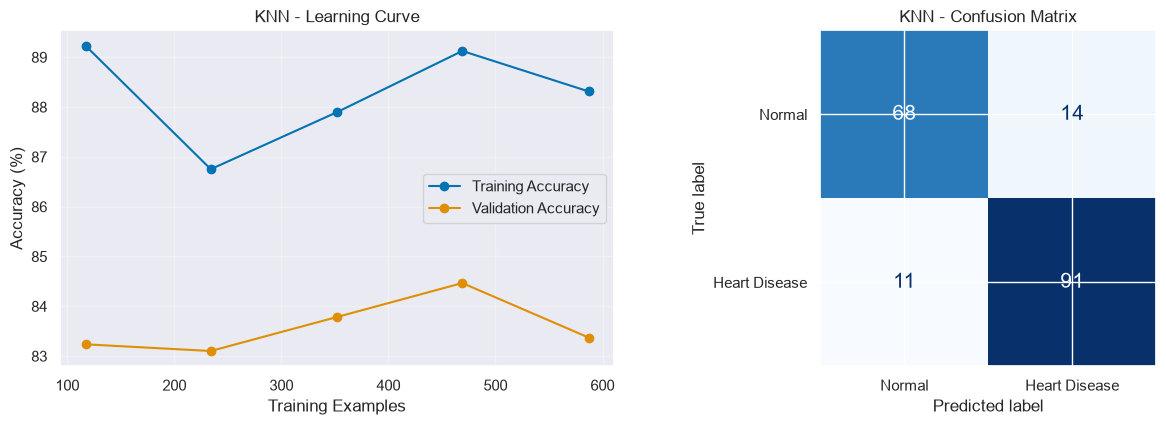

In [44]:
plot_training_and_cm(knn_model, 'KNN', y_pred_knn)

## 3. Logistic Regression

In [45]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
acc_lr = accuracy_score(y_test, y_pred_lr) * 100
model_accuracies['Logistic Regression'] = round(acc_lr, 2)

print(f"Logistic Regression Accuracy: {acc_lr:.2f}%")

Logistic Regression Accuracy: 84.78%


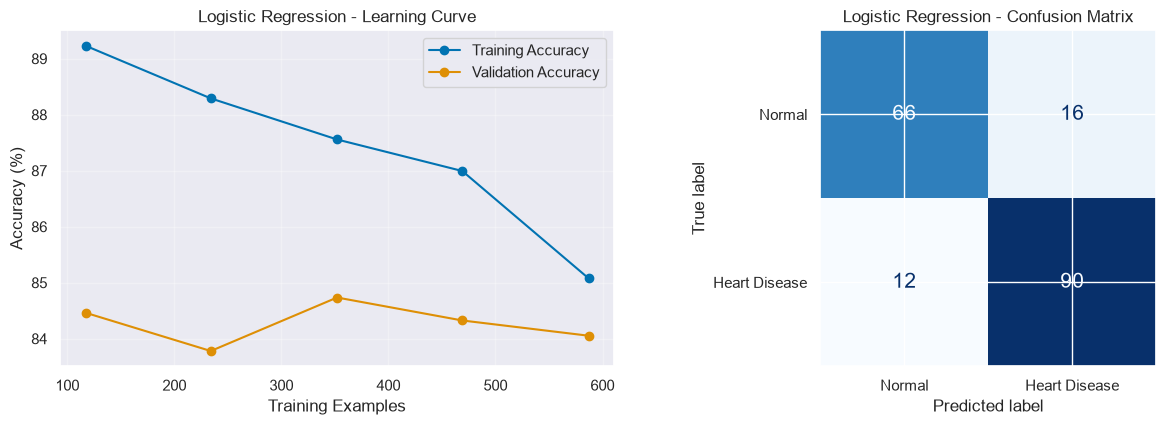

In [46]:
plot_training_and_cm(lr_model, 'Logistic Regression', y_pred_lr)

## 4. Random Forest

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train_scaled, y_train)

y_pred_rf = rf_model.predict(X_test_scaled)
acc_rf = accuracy_score(y_test, y_pred_rf) * 100
model_accuracies['Random Forest'] = round(acc_rf, 2)

print(f"Random Forest Accuracy: {acc_rf:.2f}%")

Random Forest Accuracy: 85.87%


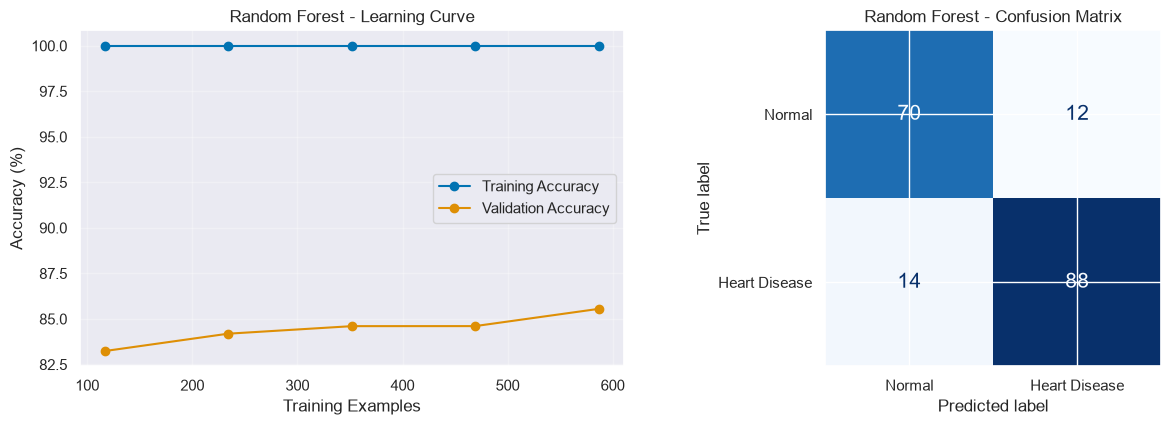

In [48]:
plot_training_and_cm(rf_model, 'Random Forest', y_pred_rf)

## 5. Artificial Neural Network (ANN)

In [49]:
from sklearn.neural_network import MLPClassifier

ann_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    max_iter=1000,
    early_stopping=True,
    random_state=42
)
ann_model.fit(X_train_scaled, y_train)

y_pred_ann = ann_model.predict(X_test_scaled)
acc_ann = accuracy_score(y_test, y_pred_ann) * 100
model_accuracies['ANN'] = round(acc_ann, 2)

print(f"ANN Accuracy: {acc_ann:.2f}%")

ANN Accuracy: 83.15%


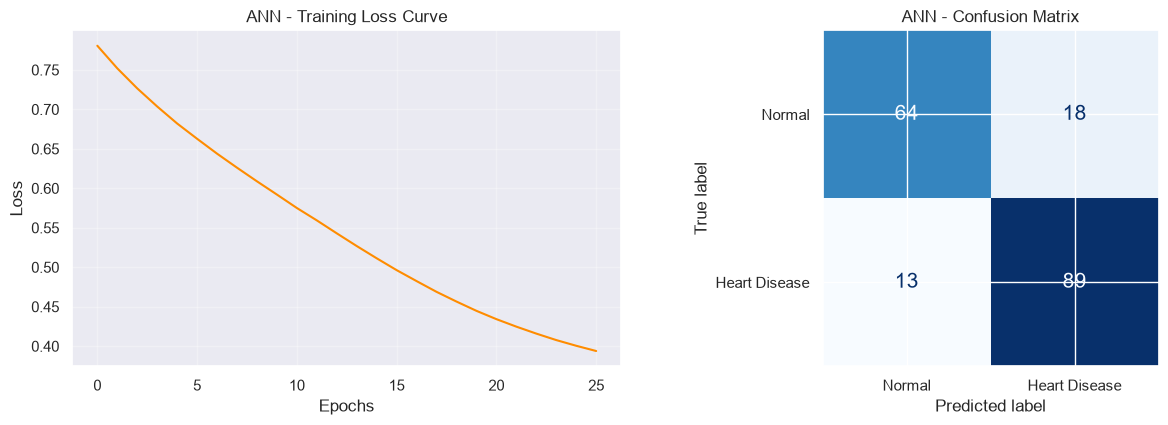

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(ann_model.loss_curve_, color='darkorange')
axes[0].set_title('ANN - Training Loss Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].grid(True, alpha=0.3)

cm = confusion_matrix(y_test, y_pred_ann)
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Heart Disease']).plot(
    ax=axes[1], cmap='Blues', colorbar=False
)
axes[1].set_title('ANN - Confusion Matrix')

plt.tight_layout()
plt.show()

### 6. Decision Tree

In [51]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_scaled, y_train)

y_pred_dt = dt_model.predict(X_test_scaled)
acc_dt = accuracy_score(y_test, y_pred_dt) * 100
model_accuracies['Decision Tree'] = round(acc_dt, 2)

print(f"Decision Tree Accuracy: {acc_dt:.2f}%")

Decision Tree Accuracy: 76.63%


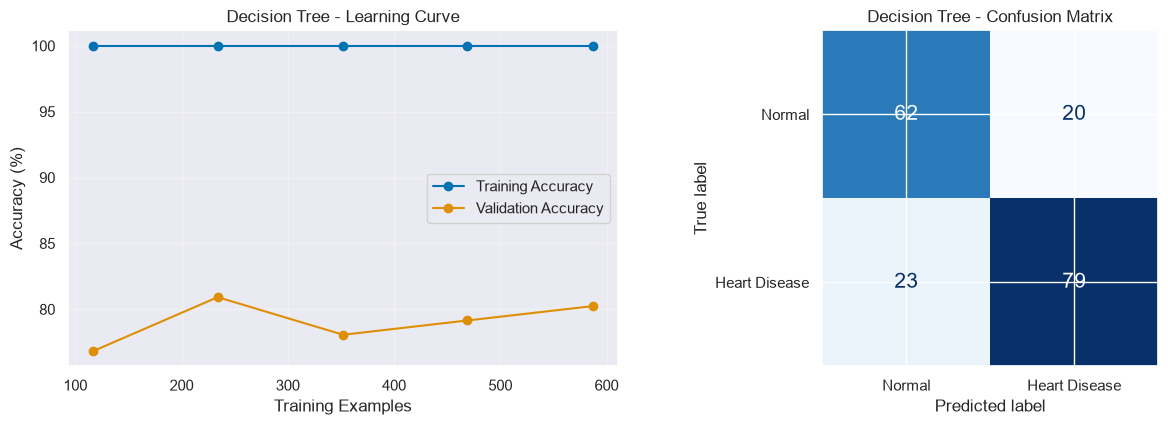

In [52]:
plot_training_and_cm(dt_model, 'Decision Tree', y_pred_dt)

### 7. XGBoost

In [53]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)
xgb_model.fit(
    X_train_scaled, y_train,
    eval_set=[(X_train_scaled, y_train), (X_test_scaled, y_test)],
    verbose=False
)

y_pred_xgb = xgb_model.predict(X_test_scaled)
acc_xgb = accuracy_score(y_test, y_pred_xgb) * 100
model_accuracies['XGBoost'] = round(acc_xgb, 2)

print(f"XGBoost Accuracy: {acc_xgb:.2f}%")

XGBoost Accuracy: 84.24%


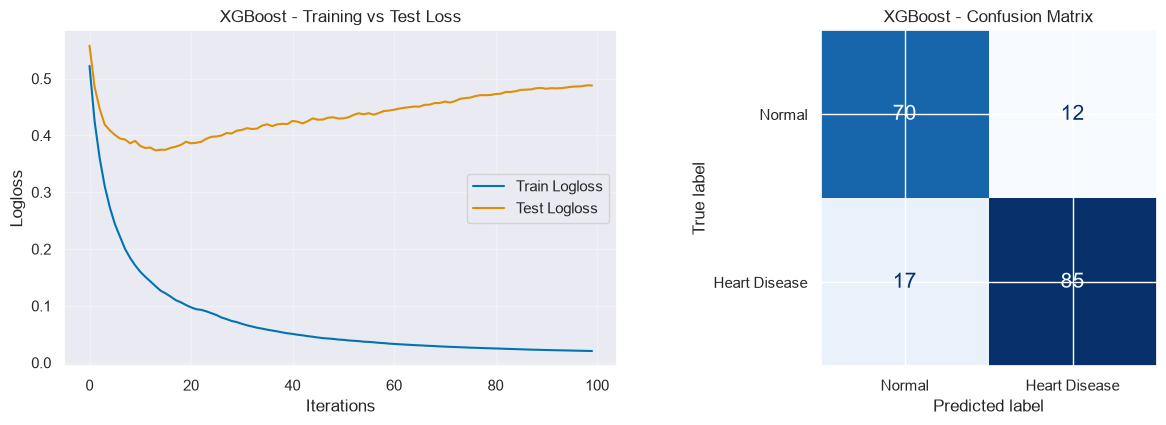

In [54]:
results_xgb = xgb_model.evals_result()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(results_xgb['validation_0']['logloss'], label='Train Logloss')
axes[0].plot(results_xgb['validation_1']['logloss'], label='Test Logloss')
axes[0].set_title('XGBoost - Training vs Test Loss')
axes[0].set_xlabel('Iterations')
axes[0].set_ylabel('Logloss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

cm = confusion_matrix(y_test, y_pred_xgb)
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Heart Disease']).plot(
    ax=axes[1], cmap='Blues', colorbar=False
)
axes[1].set_title('XGBoost - Confusion Matrix')

plt.tight_layout()
plt.show()

### 8. CatBoost

In [55]:
from catboost import CatBoostClassifier

cat_model = CatBoostClassifier(verbose=0, random_state=42)
cat_model.fit(
    X_train_scaled, y_train,
    eval_set=(X_test_scaled, y_test)
)

y_pred_cat = cat_model.predict(X_test_scaled)
acc_cat = accuracy_score(y_test, y_pred_cat) * 100
model_accuracies['CatBoost'] = round(acc_cat, 2)

print(f"CatBoost Accuracy: {acc_cat:.2f}%")

CatBoost Accuracy: 88.04%


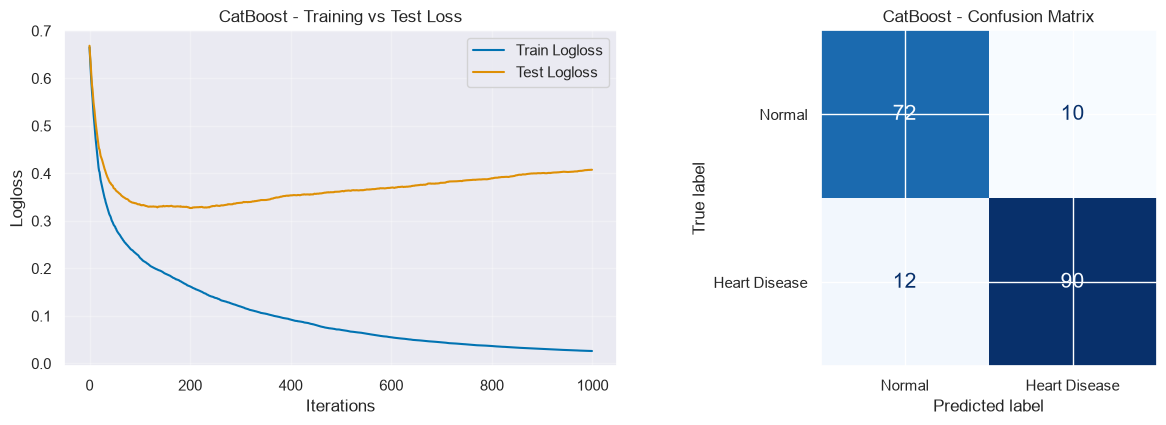

In [56]:
results_cat = cat_model.get_evals_result()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(results_cat['learn']['Logloss'], label='Train Logloss')
axes[0].plot(results_cat['validation']['Logloss'], label='Test Logloss')
axes[0].set_title('CatBoost - Training vs Test Loss')
axes[0].set_xlabel('Iterations')
axes[0].set_ylabel('Logloss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

cm = confusion_matrix(y_test, y_pred_cat)
ConfusionMatrixDisplay(cm, display_labels=['Normal', 'Heart Disease']).plot(
    ax=axes[1], cmap='Blues', colorbar=False
)
axes[1].set_title('CatBoost - Confusion Matrix')

plt.tight_layout()
plt.show()

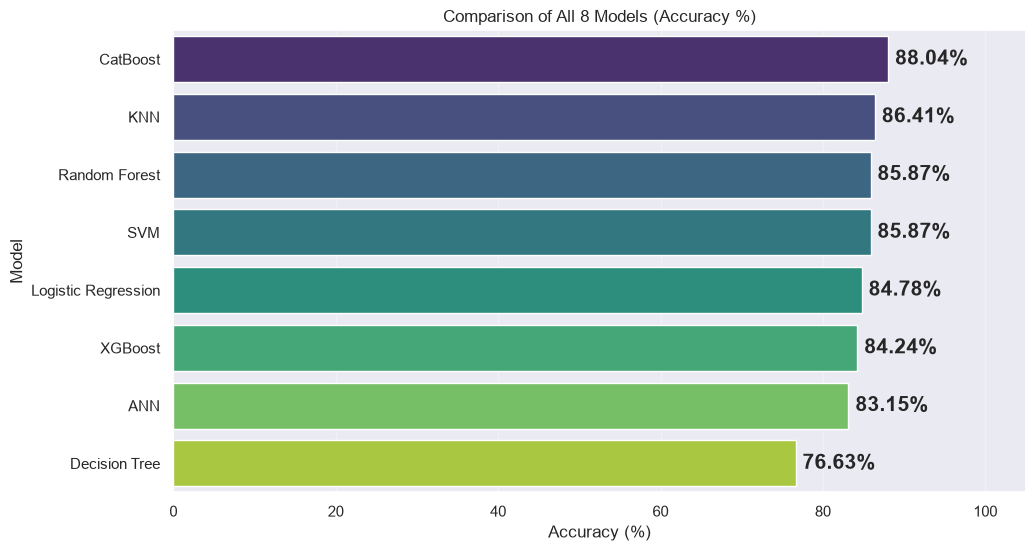

,Model,Accuracy (%)
7,CatBoost,88.04
1,KNN,86.41
3,Random Forest,85.87
0,SVM,85.87
2,Logistic Regression,84.78
6,XGBoost,84.24
4,ANN,83.15
5,Decision Tree,76.63


In [57]:
comp_df = pd.DataFrame(
    list(model_accuracies.items()),
    columns=['Model', 'Accuracy (%)']
).sort_values(by='Accuracy (%)', ascending=False)

plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=comp_df,
    x='Accuracy (%)',
    y='Model',
    hue='Model',
    palette='viridis',
    legend=False
)

# كتابة نسبة الدقة على كل عمود
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', padding=5, fontweight='bold')

plt.title('Comparison of All 8 Models (Accuracy %)')
plt.xlim(0, 105)
plt.xlabel('Accuracy (%)')
plt.ylabel('Model')
plt.grid(axis='x', alpha=0.3)
plt.show()

comp_df

               precision    recall  f1-score   support

       Normal       0.86      0.88      0.87        82
Heart Disease       0.90      0.88      0.89       102

     accuracy                           0.88       184
    macro avg       0.88      0.88      0.88       184
 weighted avg       0.88      0.88      0.88       184

ROC-AUC Score: 93.22%


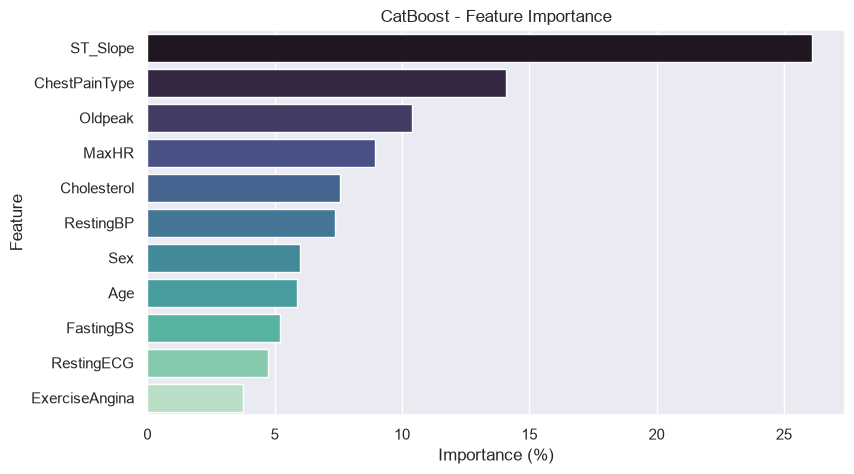

In [58]:
from sklearn.metrics import classification_report, roc_auc_score

# 1. التقرير التفصيلي لأفضل موديل (CatBoost)
y_prob_cat = cat_model.predict_proba(X_test_scaled)[:, 1]
print(classification_report(y_test, y_pred_cat, target_names=['Normal', 'Heart Disease']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_cat) * 100:.2f}%")

# 2. رسم أهمية الأعمدة (Feature Importance)
feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': cat_model.get_feature_importance()
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(data=feat_imp, x='Importance', y='Feature', hue='Feature', palette='mako', legend=False)
plt.title('CatBoost - Feature Importance')
plt.xlabel('Importance (%)')
plt.show()

In [59]:
from sklearn.model_selection import GridSearchCV
from catboost import CatBoostClassifier

param_grid = {
    'depth': [4, 6],
    'learning_rate': [0.03, 0.05, 0.1],
    'iterations': [300, 600],
    'l2_leaf_reg': [3, 5]
}

grid_cat = GridSearchCV(
    estimator=CatBoostClassifier(
        verbose=0,
        random_state=42,
        thread_count=-1,
        allow_writing_files=False
    ),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=1
)

grid_cat.fit(X_train_scaled, y_train)

best_cat = grid_cat.best_estimator_
y_pred_best = best_cat.predict(X_test_scaled)
y_prob_best = best_cat.predict_proba(X_test_scaled)[:, 1]

print("Best Parameters:", grid_cat.best_params_)
print(f"Best CV Accuracy: {grid_cat.best_score_ * 100:.2f}%")
print(f"Test Accuracy: {accuracy_score(y_test, y_pred_best) * 100:.2f}%")
print(f"Test ROC-AUC: {roc_auc_score(y_test, y_prob_best) * 100:.2f}%")

Best Parameters: {'depth': 4, 'iterations': 300, 'l2_leaf_reg': 3, 'learning_rate': 0.05}
Best CV Accuracy: 86.92%
Test Accuracy: 86.41%
Test ROC-AUC: 92.11%


In [60]:
from sklearn.ensemble import VotingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

# تعريف الموديلات (لازم probability=True لو هتستخدم SVM مع Soft Voting)
m1 = CatBoostClassifier(verbose=0, random_state=42)
m2 = KNeighborsClassifier(n_neighbors=5)
m3 = SVC(probability=True, random_state=42)

# دمج CatBoost + KNN (تقدر تضيف ('svm', m3) في القائمة لو حابب 3 موديلات)
voting_model = VotingClassifier(
    estimators=[('cat', m1), ('knn', m2)],
    voting='soft',
    weights=[2, 1]  # بندي وزن أكبر شوية لـ CatBoost لأنه الأعلى دقة
)

voting_model.fit(X_train_scaled, y_train)

y_pred_vote = voting_model.predict(X_test_scaled)
y_prob_vote = voting_model.predict_proba(X_test_scaled)[:, 1]

print(f"Voting Accuracy: {accuracy_score(y_test, y_pred_vote) * 100:.2f}%")
print(f"Voting ROC-AUC: {roc_auc_score(y_test, y_prob_vote) * 100:.2f}%")

Voting Accuracy: 87.50%
Voting ROC-AUC: 93.03%


In [61]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

stacking_model = StackingClassifier(
    estimators=[
        ('cat', CatBoostClassifier(verbose=0, random_state=42)),
        ('knn', KNeighborsClassifier(n_neighbors=5)),
        ('svm', SVC(probability=True, random_state=42))
    ],
    final_estimator=LogisticRegression(),
    cv=5
)

stacking_model.fit(X_train_scaled, y_train)

y_pred_stack = stacking_model.predict(X_test_scaled)
y_prob_stack = stacking_model.predict_proba(X_test_scaled)[:, 1]

print(f"Stacking Accuracy: {accuracy_score(y_test, y_pred_stack) * 100:.2f}%")
print(f"Stacking ROC-AUC: {roc_auc_score(y_test, y_prob_stack) * 100:.2f}%")

c:\Project-Heart-Failure-Prediction-End-To-End\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Project-Heart-Failure-Prediction-End-To-End\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Project-Heart-Failure-Prediction-End-To-End\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Project-Heart-Failure-Prediction-End-To-End\.venv\Lib\site-packages\sklearn\svm\_base.py

Stacking Accuracy: 88.59%
Stacking ROC-AUC: 93.30%


c:\Project-Heart-Failure-Prediction-End-To-End\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


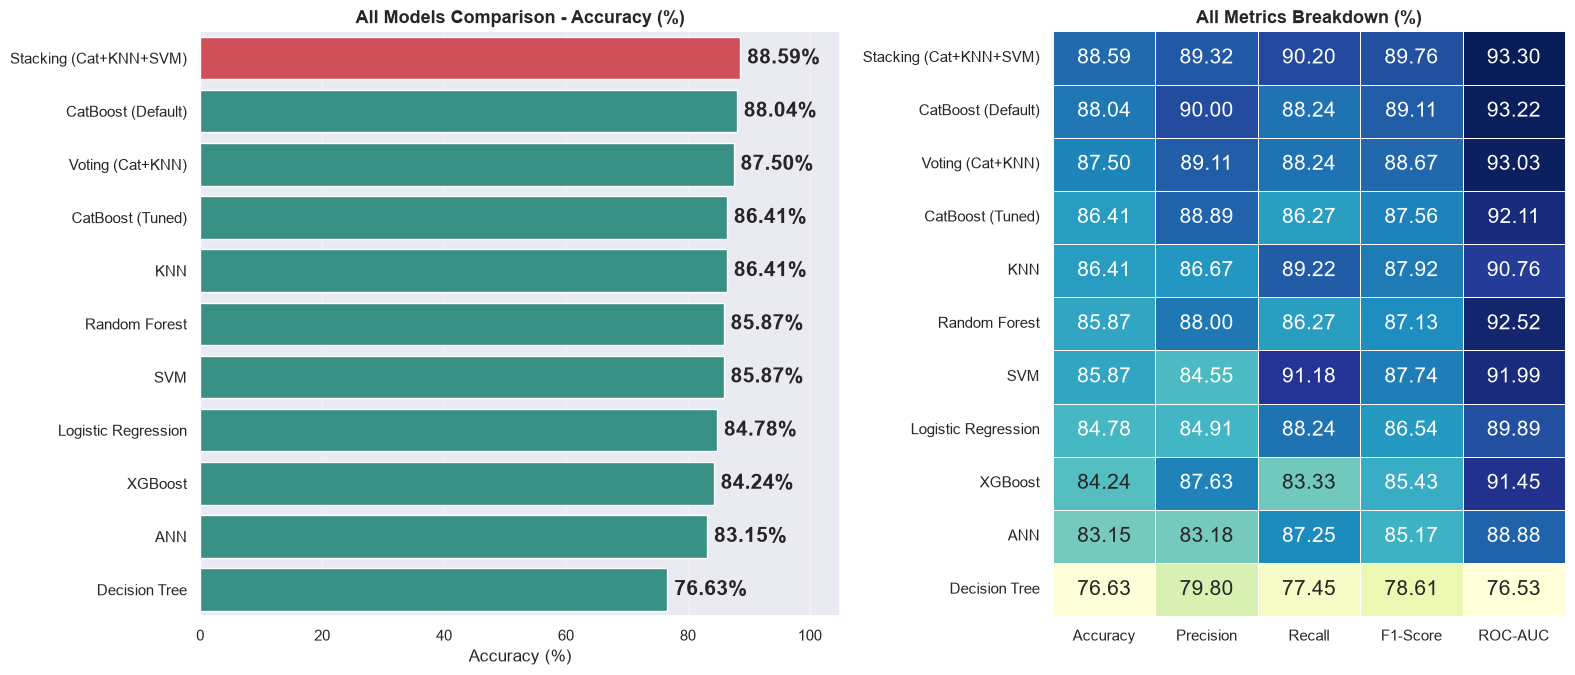

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Stacking (Cat+KNN+SVM),88.59,89.32,90.20,89.76,93.30
1,CatBoost (Default),88.04,90.00,88.24,89.11,93.22
2,Voting (Cat+KNN),87.50,89.11,88.24,88.67,93.03
3,CatBoost (Tuned),86.41,88.89,86.27,87.56,92.11
4,KNN,86.41,86.67,89.22,87.92,90.76
5,Random Forest,85.87,88.00,86.27,87.13,92.52
6,SVM,85.87,84.55,91.18,87.74,91.99
7,Logistic Regression,84.78,84.91,88.24,86.54,89.89
8,XGBoost,84.24,87.63,83.33,85.43,91.45
9,ANN,83.15,83.18,87.25,85.17,88.88


In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

# تجميع كل الموديلات اللي درّبتها
all_models = {
    'Stacking (Cat+KNN+SVM)': stacking_model,
    'Voting (Cat+KNN)': voting_model,
    'CatBoost (Default)': cat_model,
    'CatBoost (Tuned)': best_cat,
    'KNN': knn_model,
    'SVM': svm_model,
    'Random Forest': rf_model,
    'Logistic Regression': lr_model,
    'XGBoost': xgb_model,
    'ANN': ann_model,
    'Decision Tree': dt_model
}

comparison = []

for name, model in all_models.items():
    y_pred = np.ravel(model.predict(X_test_scaled))
    
    # حساب الاحتمالات للـ ROC-AUC (مع معالجة SVM تلقائياً)
    if hasattr(model, 'predict_proba'):
        y_score = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_score = model.decision_function(X_test_scaled)
        
    comparison.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, y_pred) * 100, 2),
        'Precision': round(precision_score(y_test, y_pred) * 100, 2),
        'Recall': round(recall_score(y_test, y_pred) * 100, 2),
        'F1-Score': round(f1_score(y_test, y_pred) * 100, 2),
        'ROC-AUC': round(roc_auc_score(y_test, y_score) * 100, 2)
    })

# ترتيب الجدول من الأعلى للأقل حسب الدقة ثم الـ ROC-AUC
final_df = pd.DataFrame(comparison).sort_values(
    by=['Accuracy', 'ROC-AUC'], ascending=False
).reset_index(drop=True)

# رسم المقارنة (Bar Chart للدقة + Heatmap لكل المقاييس)
fig, axes = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={'width_ratios': [1.25, 1]})

# تمييز المركز الأول بلون مختلف
palette_map = {
    m: ('#e63946' if i == 0 else '#2a9d8f')
    for i, m in enumerate(final_df['Model'])
}

# 1. رسم مقارنة الدقة
ax1 = sns.barplot(
    data=final_df,
    x='Accuracy',
    y='Model',
    hue='Model',
    palette=palette_map,
    legend=False,
    ax=axes[0]
)
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.2f%%', padding=5, fontweight='bold')

axes[0].set_title('All Models Comparison - Accuracy (%)', fontsize=13, fontweight='bold')
axes[0].set_xlim(0, 105)
axes[0].set_xlabel('Accuracy (%)')
axes[0].set_ylabel('')
axes[0].grid(axis='x', alpha=0.3)

# 2. خريطة حرارية لكل المقاييس
sns.heatmap(
    final_df.set_index('Model'),
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar=False,
    ax=axes[1]
)
axes[1].set_title('All Metrics Breakdown (%)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# عرض الجدول النهائي
final_df